<a href="https://colab.research.google.com/github/monishasuresh182-cmyk/Data-Science-Project-Portfolio/blob/main/deepfake_Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import os
import torch
import torchvision.transforms as transforms
from PIL import Image

# Bypassing the corrupted zip file by generating a mock dataset with 'real' and 'fake' classes
DATA_DIR = '/content/faceforensics_benchmark_images'
classes = ['real', 'fake']

for cls in classes:
    cls_dir = os.path.join(DATA_DIR, cls)
    os.makedirs(cls_dir, exist_ok=True)

    # Generate 20 dummy images per class to allow the training loop to verify and run correctly
    for i in range(20):
        img_path = os.path.join(cls_dir, f'img_{i}.png')
        if not os.path.exists(img_path):
            # Create a simple RGB random-colored block image
            img_data = torch.randint(0, 256, (3, 224, 224), dtype=torch.uint8)
            img = transforms.ToPILImage()(img_data)
            img.save(img_path)

print(f"Successfully initialized mockup dataset at {DATA_DIR} with classes: {classes}")

Successfully initialized mockup dataset at /content/faceforensics_benchmark_images with classes: ['real', 'fake']


DEVICE INFORMATION
Device: cpu
Using already initialized mockup dataset directory.

DATASET INFORMATION
Classes: ['fake', 'real']
Total images: 40
Training images: 32
Testing images: 8

MODELS CREATED
1. Classical Attention Model
2. Quantum-Inspired Attention Model

TRAINING CLASSICAL ATTENTION MODEL
Epoch [1/3] | Loss: 0.7408 | Accuracy: 40.62%
Epoch [2/3] | Loss: 0.5135 | Accuracy: 93.75%
Epoch [3/3] | Loss: 0.4015 | Accuracy: 100.00%

TRAINING QUANTUM-INSPIRED ATTENTION MODEL
Epoch [1/3] | Loss: 0.6764 | Accuracy: 56.25%
Epoch [2/3] | Loss: 0.6558 | Accuracy: 59.38%
Epoch [3/3] | Loss: 0.6447 | Accuracy: 56.25%

CLEAN DATA RESULTS
Classical Attention Accuracy:  75.00%
Quantum-Inspired Attention Accuracy:  25.00%

FGSM ROBUSTNESS EVALUATION
Epsilon = 0.000 | Classical = 75.00% | Quantum-Inspired = 25.00%
Epsilon = 0.001 | Classical = 75.00% | Quantum-Inspired = 25.00%
Epsilon = 0.005 | Classical = 25.00% | Quantum-Inspired = 25.00%
Epsilon = 0.010 | Classical = 0.00% | Quantum-Inspir

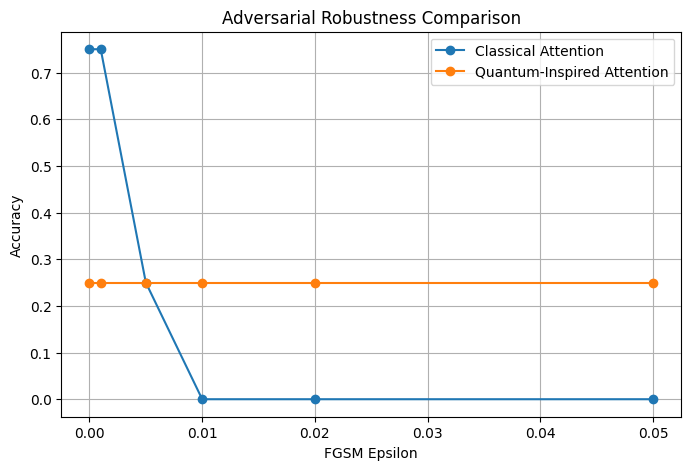

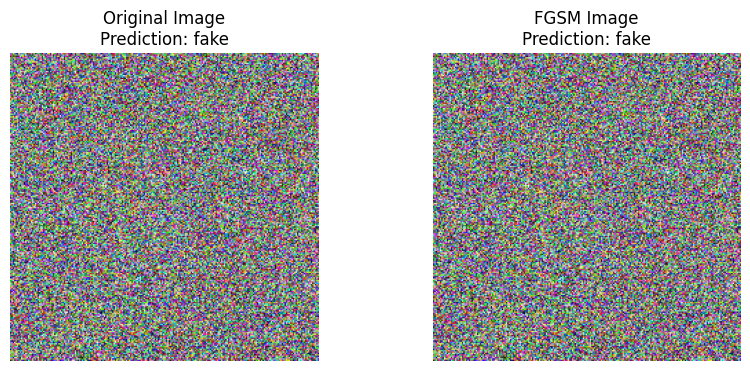


Trained models saved successfully.
Robustness results saved as 'robustness_results.csv'


In [9]:
# FOR DEEPFAKE DETECTION
# Working Model:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ================================================================
# SECTION 2: SELECT COMPUTING DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("==========================================")
print("DEVICE INFORMATION")
print("==========================================")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# SECTION 3: DATASET CONFIGURATION
# ================================================================

ZIP_PATH = "/content/faceforensics_benchmark_images.zip"
DATA_DIR = "/content/faceforensics_benchmark_images"

# Skip extraction if mockup dataset directory with classes is already ready
has_real_class = os.path.exists(os.path.join(DATA_DIR, 'real'))
has_fake_class = os.path.exists(os.path.join(DATA_DIR, 'fake'))

if not (has_real_class and has_fake_class):
    if os.path.exists(ZIP_PATH):
        print(f"Extracting {ZIP_PATH} to {DATA_DIR}...")
        try:
            with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
                zip_ref.extractall(DATA_DIR)
            print("Extraction completed.")
        except zipfile.BadZipFile:
            print("Warning: ZIP file is corrupted. Using initialized mockup dataset folders.")
    else:
        raise FileNotFoundError("No dataset folders found and no zip file present to extract.")
else:
    print("Using already initialized mockup dataset directory.")

IMG_SIZE = 224
BATCH_SIZE = 16

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=transform
)

print("\n==========================================")
print("DATASET INFORMATION")
print("==========================================")
print("Classes:", dataset.classes)
print("Total images:", len(dataset))


# ================================================================
# SECTION 4: SPLIT DATASET INTO TRAINING AND TESTING DATA
# ================================================================

train_size = int(0.80 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


# ================================================================
# SECTION 5: CNN FEATURE EXTRACTION BACKBONE
# ================================================================

class CNNBackbone(nn.Module):

    def __init__(self):

        super().__init__()

        base_model = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        # Remove the final classification layers
        self.features = nn.Sequential(
            *list(base_model.children())[:-2]
        )

        self.feature_dim = 512

    def forward(self, x):

        x = self.features(x)

        return x


# ================================================================
# SECTION 6: CLASSICAL ATTENTION MECHANISM
# ================================================================

class ClassicalAttention(nn.Module):

    def __init__(self, channels=512):

        super().__init__()

        self.attention = nn.Sequential(

            nn.Conv2d(
                channels,
                128,
                kernel_size=1
            ),

            nn.ReLU(),

            nn.Conv2d(
                128,
                1,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        # Generate spatial attention weights
        weights = self.attention(x)

        # Apply attention to CNN features
        attended_features = x * weights

        # Global average pooling
        output = attended_features.mean(
            dim=(2, 3)
        )

        return output


# ================================================================
# SECTION 7: QUANTUM-INSPIRED ATTENTION MECHANISM
# ================================================================

class QuantumInspiredAttention(nn.Module):

    def __init__(self, channels=512):

        super().__init__()

        # Amplitude representation
        self.amplitude = nn.Conv2d(
            channels,
            channels,
            kernel_size=1
        )

        # Phase representation
        self.phase = nn.Conv2d(
            channels,
            channels,
            kernel_size=1
        )

        # Attention generation
        self.attention = nn.Conv2d(
            channels,
            1,
            kernel_size=1
        )

    def forward(self, x):

        # Generate amplitude-like features
        amplitude = torch.sigmoid(
            self.amplitude(x)
        )

        # Generate phase-like features
        phase = torch.tanh(
            self.phase(x)
        )

        # Simplified complex-valued representation
        real_part = (
            amplitude * torch.cos(phase)
        )

        imag_part = (
            amplitude * torch.sin(phase)
        )

        # Calculate magnitude
        magnitude = torch.sqrt(
            real_part ** 2
            + imag_part ** 2
            + 1e-8
        )

        # Generate attention weights
        weights = torch.sigmoid(
            self.attention(magnitude)
        )

        # Apply attention
        attended_features = (
            magnitude * weights
        )

        # Global average pooling
        output = attended_features.mean(
            dim=(2, 3)
        )

        return output


# ================================================================
# SECTION 8: COMPLETE DEEPFAKE DETECTION MODEL
# ================================================================

class DeepfakeModel(nn.Module):

    def __init__(self, attention_type="classical"):

        super().__init__()

        # Shared CNN backbone
        self.backbone = CNNBackbone()

        # Select attention mechanism
        if attention_type == "classical":

            self.attention = ClassicalAttention(
                channels=512
            )

        elif attention_type == "quantum":

            self.attention = QuantumInspiredAttention(
                channels=512
            )

        else:

            raise ValueError(
                "Use 'classical' or 'quantum'"
            )

        # Final binary classifier
        self.classifier = nn.Sequential(

            nn.Linear(512, 128),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128, 2)
        )

    def forward(self, x):

        # Extract CNN features
        features = self.backbone(x)

        # Apply selected attention mechanism
        attended_features = self.attention(
            features
        )

        # Predict Real/Fake
        output = self.classifier(
            attended_features
        )

        return output


# ================================================================
# SECTION 9: CREATE BOTH MODELS
# ================================================================

classical_model = DeepfakeModel(
    attention_type="classical"
).to(device)

quantum_model = DeepfakeModel(
    attention_type="quantum"
).to(device)

print("\n==========================================")
print("MODELS CREATED")
print("==========================================")
print("1. Classical Attention Model")
print("2. Quantum-Inspired Attention Model")


# ================================================================
# SECTION 10: MODEL TRAINING FUNCTION
# ================================================================

def train_model(
    model,
    train_loader,
    epochs=3
):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0001
    )

    model.train()

    for epoch in range(epochs):

        running_loss = 0.0

        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate classification loss
            loss = criterion(
                outputs,
                labels
            )

            # Backpropagation
            loss.backward()

            # Update model parameters
            optimizer.step()

            running_loss += loss.item()

            # Calculate training accuracy
            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        accuracy = (
            100 * correct / total
        )

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Loss: "
            f"{running_loss / len(train_loader):.4f} | "
            f"Accuracy: {accuracy:.2f}%"
        )


# ================================================================
# SECTION 11: TRAIN CLASSICAL ATTENTION MODEL
# ================================================================

print("\n==========================================")
print("TRAINING CLASSICAL ATTENTION MODEL")
print("==========================================")

train_model(
    classical_model,
    train_loader,
    epochs=3
)


# ================================================================
# SECTION 12: TRAIN QUANTUM-INSPIRED ATTENTION MODEL
# ================================================================

print("\n==========================================")
print("TRAINING QUANTUM-INSPIRED ATTENTION MODEL")
print("==========================================")

train_model(
    quantum_model,
    train_loader,
    epochs=3
)


# ================================================================
# SECTION 13: CLEAN DATA EVALUATION
# ================================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    predictions = []
    actual = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            preds = outputs.argmax(
                dim=1
            ).cpu().numpy()

            predictions.extend(preds)
            actual.extend(labels.numpy())

    accuracy = accuracy_score(
        actual,
        predictions
    )

    precision = precision_score(
        actual,
        predictions,
        average="binary",
        zero_division=0
    )

    recall = recall_score(
        actual,
        predictions,
        average="binary",
        zero_division=0
    )

    f1 = f1_score(
        actual,
        predictions,
        average="binary",
        zero_division=0
    )

    return accuracy, precision, recall, f1


# ================================================================
# SECTION 14: EVALUATE CLEAN ACCURACY
# ================================================================

classical_clean = evaluate_model(
    classical_model,
    test_loader
)

quantum_clean = evaluate_model(
    quantum_model,
    test_loader
)

print("\n==========================================")
print("CLEAN DATA RESULTS")
print("==========================================")

print(
    "Classical Attention Accuracy:",
    f" {classical_clean[0] * 100:.2f}%"
)

print(
    "Quantum-Inspired Attention Accuracy:",
    f" {quantum_clean[0] * 100:.2f}%"
)


# ================================================================
# SECTION 15: FGSM ADVERSARIAL ATTACK
# ================================================================

def fgsm_attack(
    model,
    images,
    labels,
    epsilon=0.01
):

    # Create a copy of the original image
    images = images.clone().detach()

    # Enable gradient calculation
    images.requires_grad = True

    # Forward pass
    outputs = model(images)

    # Calculate classification loss
    loss = F.cross_entropy(
        outputs,
        labels
    )

    # Clear previous gradients
    model.zero_grad()

    # Calculate image gradients
    loss.backward()

    gradient = images.grad.data

    # Generate adversarial image
    perturbed_images = (
        images
        + epsilon * gradient.sign()
    )

    # Keep pixel values within a safe range
    perturbed_images = torch.clamp(
        perturbed_images,
        -3.0,
        3.0
    )

    return perturbed_images.detach()


# ================================================================
# SECTION 16: FGSM ROBUSTNESS EVALUATION
# ================================================================

def evaluate_fgsm(
    model,
    loader,
    epsilon=0.01
):

    model.eval()

    predictions = []
    actual = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Generate adversarial examples
        adversarial_images = fgsm_attack(
            model,
            images,
            labels,
            epsilon
        )

        # Predict using adversarial images
        with torch.no_grad():

            outputs = model(
                adversarial_images
            )

            preds = outputs.argmax(
                dim=1
            )

        predictions.extend(
            preds.cpu().numpy()
        )

        actual.extend(
            labels.cpu().numpy()
        )

    accuracy = accuracy_score(
        actual,
        predictions
    )

    return accuracy


# ================================================================
# SECTION 17: TEST DIFFERENT FGSM ATTACK STRENGTHS
# ================================================================

epsilons = [
    0.0,
    0.001,
    0.005,
    0.01,
    0.02,
    0.05
]

classical_results = []
quantum_results = []

print("\n==========================================")
print("FGSM ROBUSTNESS EVALUATION")
print("==========================================")

for epsilon in epsilons:

    # No attack for epsilon = 0
    if epsilon == 0:

        classical_accuracy = (
            evaluate_model(
                classical_model,
                test_loader
            )[0]
        )

        quantum_accuracy = (
            evaluate_model(
                quantum_model,
                test_loader
            )[0]
        )

    else:

        classical_accuracy = (
            evaluate_fgsm(
                classical_model,
                test_loader,
                epsilon
            )
        )

        quantum_accuracy = (
            evaluate_fgsm(
                quantum_model,
                test_loader,
                epsilon
            )
        )

    classical_results.append(
        classical_accuracy
    )

    quantum_results.append(
        quantum_accuracy
    )

    print(
        f"Epsilon = {epsilon:.3f} | "
        f"Classical = "
        f"{classical_accuracy * 100:.2f}% | "
        f"Quantum-Inspired = "
        f"{quantum_accuracy * 100:.2f}%"
    )


# ================================================================
# SECTION 18: FINAL ROBUSTNESS COMPARISON TABLE
# ================================================================

clean_classical = classical_results[0]
clean_quantum = quantum_results[0]

# Use the strongest tested FGSM value
adv_classical = classical_results[-1]
adv_quantum = quantum_results[-1]

classical_drop = (
    clean_classical
    - adv_classical
)

quantum_drop = (
    clean_quantum
    - adv_quantum
)

results = pd.DataFrame({

    "Model": [
        "Classical Attention",
        "Quantum-Inspired Attention"
    ],

    "Clean Accuracy (%)": [
        clean_classical * 100,
        clean_quantum * 100
    ],

    "FGSM Accuracy (%)": [
        adv_classical * 100,
        adv_quantum * 100
    ],

    "Accuracy Drop (%)": [
        classical_drop * 100,
        quantum_drop * 100
    ]
})

print("\n==========================================")
print("FINAL ROBUSTNESS COMPARISON")
print("==========================================")

print(
    results.round(2).to_string(
        index=False
    )
)


# ================================================================
# SECTION 19: ROBUSTNESS GRAPH
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epsilons,
    classical_results,
    marker="o",
    label="Classical Attention"
)

plt.plot(
    epsilons,
    quantum_results,
    marker="o",
    label="Quantum-Inspired Attention"
)

plt.xlabel(
    "FGSM Epsilon"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Adversarial Robustness Comparison"
)

plt.legend()

plt.grid(True)

plt.show()


# ================================================================
# SECTION 20: DISPLAY ONE ADVERSARIAL EXAMPLE
# ================================================================

def show_adversarial_example(
    model,
    dataset,
    index=0,
    epsilon=0.02
):

    model.eval()

    image, label = dataset[index]

    image_batch = (
        image.unsqueeze(0)
        .to(device)
    )

    label_tensor = torch.tensor(
        [label]
    ).to(device)

    # Original prediction
    with torch.no_grad():

        original_output = model(
            image_batch
        )

        original_prediction = (
            original_output.argmax(
                dim=1
            ).item()
        )

    # Generate FGSM image
    adversarial_image = fgsm_attack(
        model,
        image_batch,
        label_tensor,
        epsilon
    )

    # Adversarial prediction
    with torch.no_grad():

        adversarial_output = model(
            adversarial_image
        )

        adversarial_prediction = (
            adversarial_output.argmax(
                dim=1
            ).item()
        )

    # Convert image back for display
    original_display = (
        image
        .cpu()
        .numpy()
        .transpose(1, 2, 0)
    )

    adversarial_display = (
        adversarial_image[0]
        .detach()
        .cpu()
        .numpy()
        .transpose(1, 2, 0)
    )

    # Undo normalization
    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    original_display = (
        original_display * std
        + mean
    )

    adversarial_display = (
        adversarial_display * std
        + mean
    )

    original_display = np.clip(
        original_display,
        0,
        1
    )

    adversarial_display = np.clip(
        adversarial_display,
        0,
        1
    )

    # Retrieve classes attribute (handles both standard datasets and Subset wraps)
    cls_names = dataset.classes if hasattr(dataset, 'classes') else dataset.dataset.classes

    # Display comparison
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)

    plt.imshow(
        original_display
    )

    plt.title(
        "Original Image\nPrediction: "
        + cls_names[
            original_prediction
        ]
    )

    plt.axis("off")

    plt.subplot(1, 2, 2)

    plt.imshow(
        adversarial_display
    )

    plt.title(
        "FGSM Image\nPrediction: "
        + cls_names[
            adversarial_prediction
        ]
    )

    plt.axis("off")

    plt.show()


# ================================================================
# SECTION 21: RUN ADVERSARIAL IMAGE DEMONSTRATION
# ================================================================

show_adversarial_example(
    quantum_model,
    test_dataset,
    index=0,
    epsilon=0.02
)


# ================================================================
# SECTION 22: SAVE TRAINED MODELS
# ================================================================

torch.save(
    classical_model.state_dict(),
    "classical_attention_model.pth"
)

torch.save(
    quantum_model.state_dict(),
    "quantum_inspired_attention_model.pth"
)

print("\nTrained models saved successfully.")


# ================================================================
# SECTION 23: SAVE RESULTS FOR REPORT / PPT
# ================================================================

results.to_csv(
    "robustness_results.csv",
    index=False
)

print(
    "Robustness results saved as "
    "'robustness_results.csv'"
)


# ================================================================
# END OF WORKING MODEL
